# Deep Learning Framework for Environmental Sound Recognition Using PyTorch

**Notebook 02 · Validation experiments and held-out evaluation**

UrbanSound8K · Official AudioSet-pretrained PANNs CNN14 · 10 classes

> **Completed evidence · 30 October 2026:** Three six-epoch freezing-depth experiments were compared using validation fold 2. The selected `block6` checkpoint (epoch 4) was evaluated **once** on held-out fold 1 (873 recordings): **88.55% accuracy**, **0.8964 macro-F1** and **0.9909 macro OvR ROC-AUC**. The original results are stored in [faculty evidence](../reports/faculty_evidence/heldout/).

### Notebook map

1. Safe controls and experiment provenance
2. Three-method validation comparison and learning curves
3. Compute/parameter trade-offs and validation-based selection
4. Optional *reproduction* of selected-model fold-1 evaluation
5. Read-only test artifacts and README synchronization

**For a reviewer:** use the saved outputs and read-only cells. Do not rerun training or the final test just to inspect the project. [Notebook 01](01_UrbanSound8K_PANNs_CNN14_Project.ipynb) explains preprocessing and freezing; [Notebook 03](03_CO4_CO5_Faculty_Submission.ipynb) covers CO4/CO5.


## 1 · Safe execution controls

Default settings display saved results without installing packages, training, clearing caches or running test inference. Evaluation and README writes require explicit switches.

**Evaluation discipline:** `block6` was selected using validation fold 2 *before* fold 1 was tested. The held-out result is final evidence—not a signal to retune hyperparameters or select another method.


In [ ]:
RUN_HELDOUT_TEST = False   # Set True only after selecting a verified block6 best.pt
UPDATE_ROOT_README = True  # Set True to insert/update the evidence section, preserving other text

# Replace None with the actual Stage 4 run directory containing block6 best.pt
# Example: r"D:\EnvironmentalSoundRecognition\results\stage4\20261027_123456_123456_block6_test1"
SELECTED_BLOCK6_RUN_DIR = r"D:\EnvironmentalSoundRecognition\results\stage4\20261027_144004_603447_block6_test1"

# Real inference on 873 test files; batch 1 is conservative for the 4 GiB RTX 3050.
TEST_BATCH_SIZE = 1
TEST_AMP_MODE = 'auto'  # BF16 on supported CUDA GPUs, otherwise FP32
TEST_DEVICE = 'auto'

print('Test evaluation enabled:', RUN_HELDOUT_TEST)
print('README synchronization enabled:', UPDATE_ROOT_README)

Test evaluation enabled: False
README synchronization enabled: False


## 2 · Project paths and result provenance

The notebook locates the project root regardless of whether VS Code starts in the root or `notebooks/`. Comparison tables come from the **actual six-epoch histories** in `reports/faculty_evidence/training_runs/` or the corresponding local experiment folders—not simulated results.

Verified original environment: PyTorch `2.7.0+cu128` on Windows/Python 3.13. The official PANNs source revision is `d2f4b8c18eab44737fcc0de1248ae21eb43f6aa4`.


In [2]:
from pathlib import Path
import sys, json, os, subprocess, datetime
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'src'/'dataset.py').is_file() and (p/'reports'/'stage4_comparison'/'stage4_comparison.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook inside the project root after extracting the Stage5 kit.')
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
REVIEW = ROOT/'reports'/'stage4_comparison'
print('Project root:', ROOT)
print('Python kernel:', sys.executable)
print('Stage 4 analysis directory:', REVIEW)
import torch
print('Torch:', torch.__version__, 'CUDA:', torch.cuda.is_available())

Project root: D:\EnvironmentalSoundRecognition
Python kernel: c:\Program Files\Python313\python.exe
Stage 4 analysis directory: D:\EnvironmentalSoundRecognition\reports\stage4_comparison
Torch: 2.7.0+cu128 CUDA: True


## 3 · CO5 experiment: freezing-depth comparison

Each method trained on folds 3–10 (6,971 clips), used fold 2 for validation (888), and reserved fold 1 for testing (873). Fixed settings: **seed 67**, six epochs, batch size 1, accumulation 4, BF16, AdamW, cross-entropy and the same learning-rate/weight-decay policy.

| Method | Trainable parameters | Best validation accuracy | Best validation macro-F1 |
|---|---:|---:|---:|
| Frozen CNN14 + head | 20,490 | 87.73% | 0.8638 |
| `fc1` + head | 4,216,842 | 88.06% | 0.8668 |
| **`conv_block6` + `fc1` + head** | **60,848,138** | **90.65%** | **0.9010** |

The **experimental variable** was the set of trainable pretrained layers. This is a single-split ablation, not a statistically powered ten-fold study.


In [3]:
comparison = pd.read_csv(REVIEW/'stage4_comparison.csv')
assert set(comparison.configuration) == {'head', 'fc1', 'block6'}
assert (comparison.best_epoch == 4).all()
assert (~comparison.test_evaluated.astype(bool)).all()
columns = ['configuration','best_epoch','best_val_accuracy_pct','best_val_macro_f1',
           'trainable_parameters','total_six_epoch_minutes','peak_gpu_mib']
display(comparison[columns].set_index('configuration'))
head_row = comparison.set_index('configuration').loc['head']
block_row = comparison.set_index('configuration').loc['block6']
print(f"Block6 – head: {block_row.best_val_accuracy_pct-head_row.best_val_accuracy_pct:.2f} percentage points accuracy")
print(f"Block6 – head: {block_row.best_val_macro_f1-head_row.best_val_macro_f1:.4f} macro-F1")
print('FINAL TEST STATUS: NOT EVALUATED')

,best_epoch,best_val_accuracy_pct,best_val_macro_f1,trainable_parameters,total_six_epoch_minutes,peak_gpu_mib
configuration,,,,,,
head,4,87.7252,0.863776,20490,19.80,474.2
fc1,4,88.0631,0.866844,4216842,18.87,522.3
block6,4,90.6532,0.900967,60848138,28.65,1278.1


Block6 – head: 2.93 percentage points accuracy
Block6 – head: 0.0372 macro-F1
FINAL TEST STATUS: NOT EVALUATED


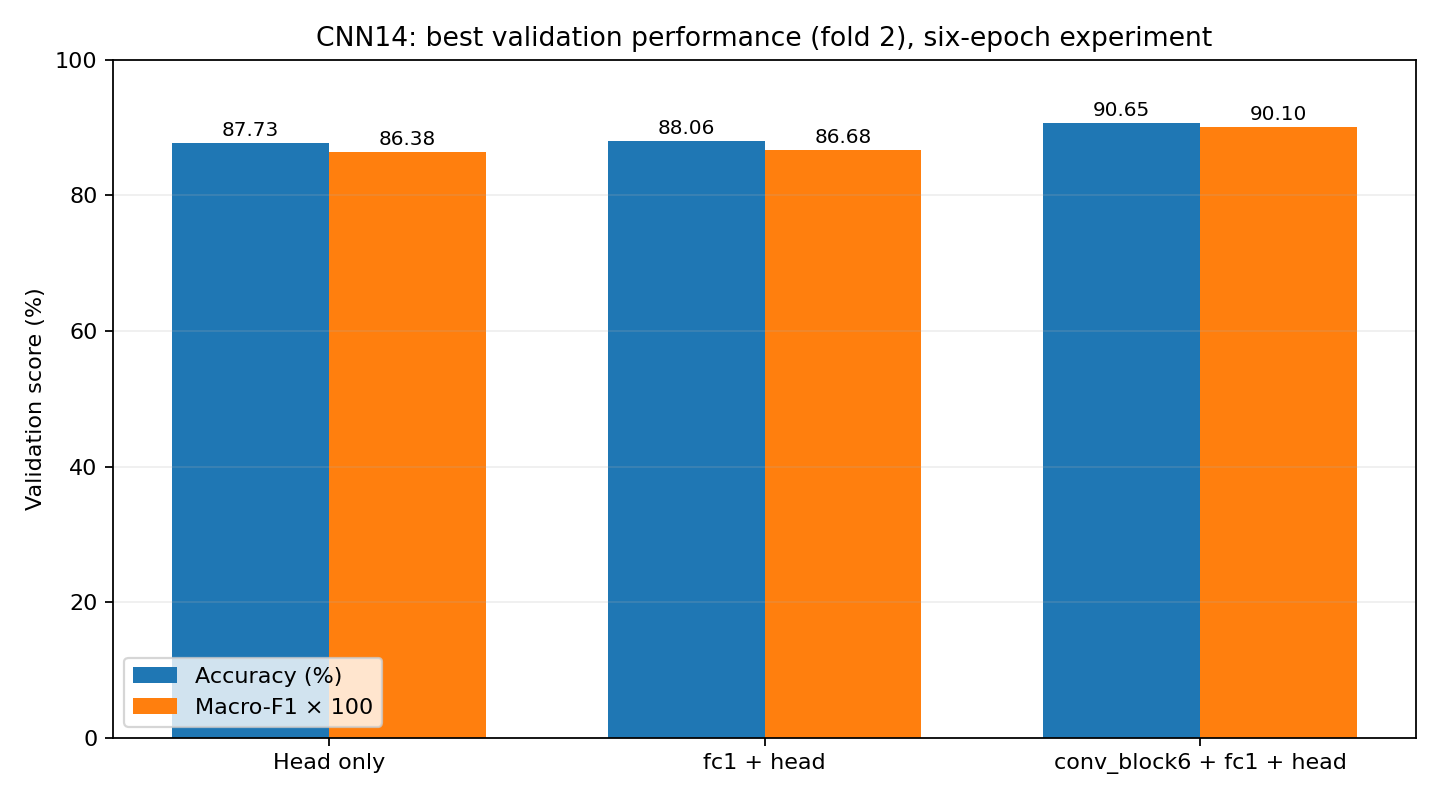

In [4]:
display(Image(filename=str(REVIEW/'validation_comparison.png'), width=850))

## 4 · Learning dynamics and checkpoint choice

All three configurations selected **epoch 4**, maximizing validation macro-F1. After that, validation loss increased while training loss continued declining; for `block6`, validation loss rose from **0.3433 (epoch 4)** to **0.3986 (epoch 6)**.

**Why the best checkpoint matters:** evaluate the saved epoch-4 `best.pt`, not epoch-6 weights. Training accuracy is measured online under SpecAugmentation/dropout, while validation is measured in evaluation mode. Their direct difference is not a strict like-for-like generalization-gap estimate.


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1,optimizer_steps
configuration,,,,,,,
head,4,0.555166,0.829580,0.410351,0.877252,0.863776,1743
fc1,4,0.533377,0.837039,0.402933,0.880631,0.866844,1743
block6,4,0.382325,0.889686,0.343293,0.906532,0.900967,1743


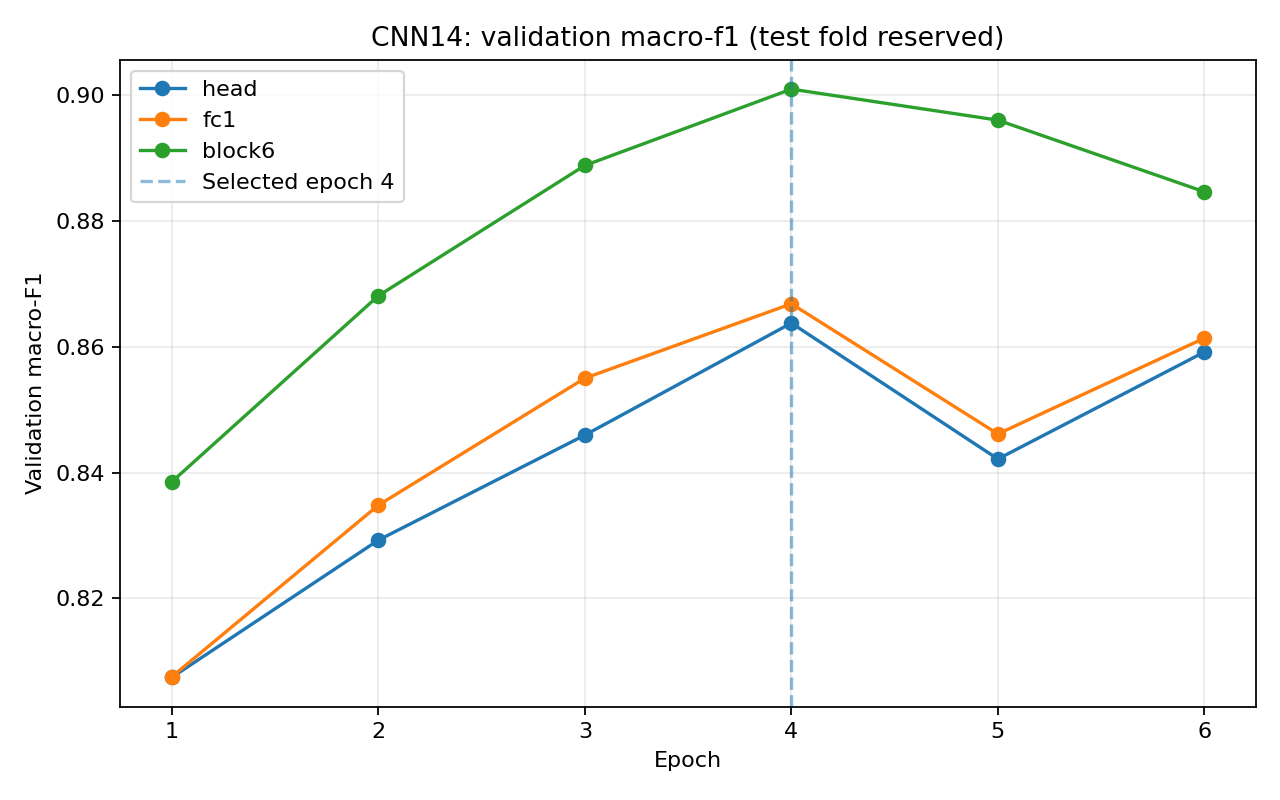

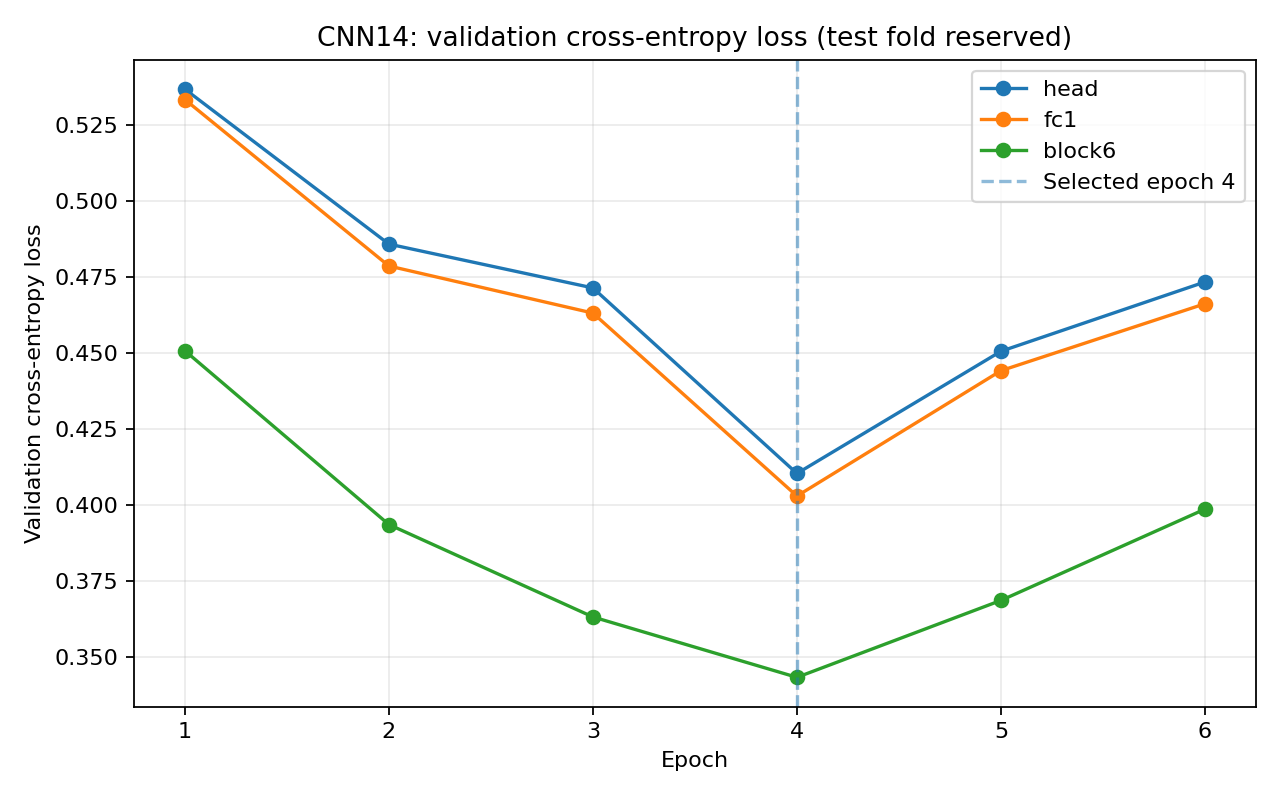

In [5]:
all_epochs = pd.read_csv(REVIEW/'stage4_all_epochs.csv')
selected = all_epochs.loc[all_epochs.epoch==4, ['configuration','epoch','train_loss','train_accuracy','val_loss','val_accuracy','val_macro_f1','optimizer_steps']]
display(selected.set_index('configuration'))
display(Image(filename=str(REVIEW/'macro_f1_by_epoch.png'), width=820))
display(Image(filename=str(REVIEW/'val_loss_by_epoch.png'), width=820))

## 5 · Accuracy–compute trade-off and caveats

`block6` trains **60,848,138 / 81,857,561 total parameters (~74.3%)**, compared with 20,490 for head-only. The six-epoch runtime was about **28.65 min**, versus **19.80 min** head-only; observed peak allocated GPU memory was about **1,278 MiB** for `block6`.

The improvement is measured **on one validation fold and one seed**. It does not establish cross-fold stability, statistical significance or parameter efficiency. Five original Freesound `fsID` values also span predefined folds; source-level independence is imperfect.


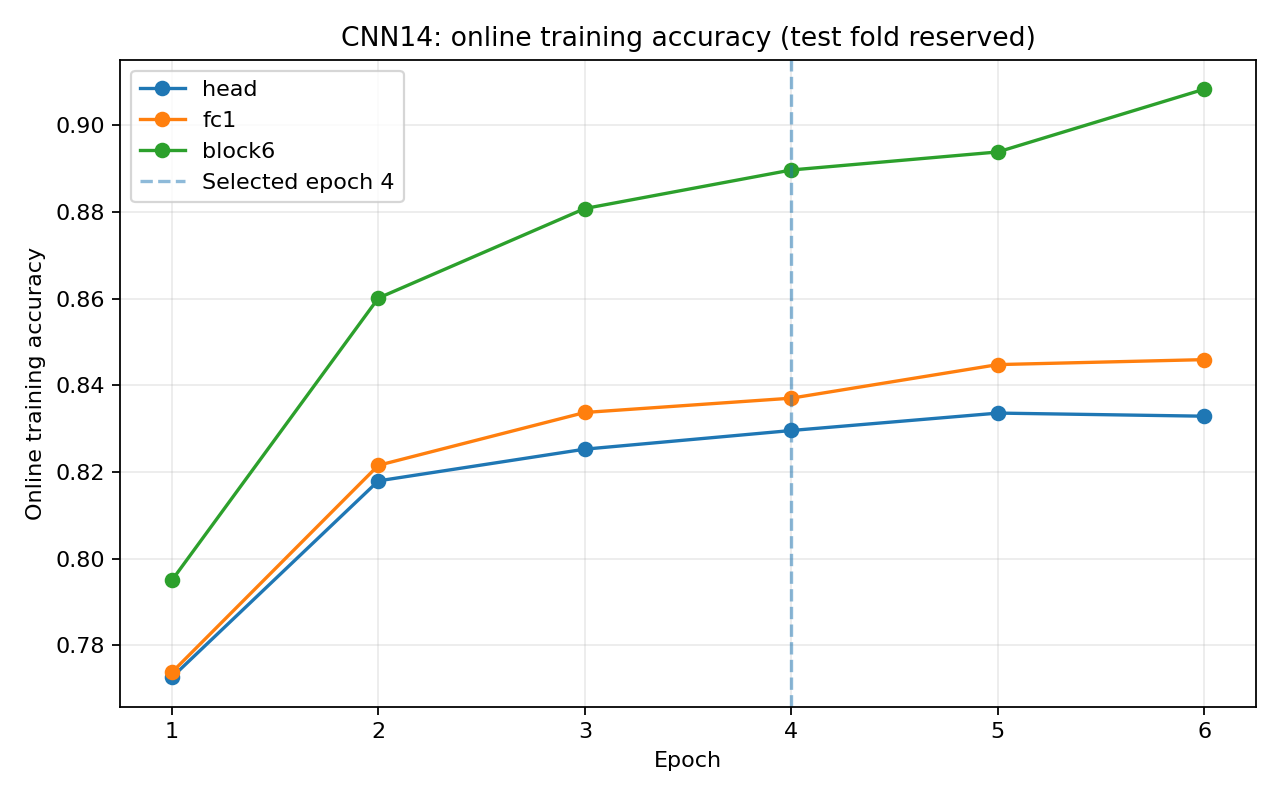

# Stage 4 Experiment Review — 27 October 2026

**Project:** Deep Learning Framework for Environmental Sound Recognition Using PyTorch  
**Evidence:** the supplied `Stage4_Three_Full_Runs_Review.zip` (three configurations × `config.json`, `summary.json`, `history.csv`, `learning_curves.png`).

## Controlled validation results (not held-out test results)

| Configuration | Best epoch | Validation accuracy | Validation macro-F1 | Trainable parameters | Six-epoch time | Peak CUDA allocated |
|:--|--:|--:|--:|--:|--:|--:|
| Head only | 4 | 87.73% | 0.8638 | 20,490 | 19.80 min | 474.2 MiB |
| fc1 + head | 4 | 88.06% | 0.8668 | 4,216,842 | 18.87 min | 522.3 MiB |
| conv_block6 + fc1 + head | **4** | **90.65%** | **0.9010** | **60,848,138** | 28.65 min | 1278.1 MiB |

The `block6` model exceeded the head-only baseline by **2.93 percentage points** in validation accuracy and **0.0372 absolute macro-F1**. Compared with fc1, accuracy increased by **2.59 percentage points**. These are validation-s

In [6]:
display(Image(filename=str(REVIEW/'train_accuracy_by_epoch.png'), width=820))
print((REVIEW/'STAGE4_REVIEW.md').read_text(encoding='utf-8')[:4500])

## 6 · Selected model: validation first, test second

The selected candidate was **`block6`, checkpoint epoch 4** (validation macro-F1 **0.9009665**, accuracy **0.9065315**). The original local run directory was:

`results/stage4/20261027_144004_603447_block6_test1/`

Its `best.pt` stores **only the trainable parameter tensors**, not a complete CNN14 model. The full backbone must be reconstructed from the pinned official AudioSet weights before applying this checkpoint. Expected selected-checkpoint SHA-256 begins `7c0e01a0`; see [checkpoint access](../models/CHECKPOINT_ACCESS.md) for the full hash and replay steps.


In [7]:
STAGE4_DIR = ROOT/'results'/'stage4'
matching = []
if STAGE4_DIR.is_dir():
    for folder in sorted(STAGE4_DIR.iterdir()):
        if not folder.is_dir(): continue
        cfg_file, summary_file = folder/'config.json', folder/'summary.json'
        if not cfg_file.exists() or not summary_file.exists(): continue
        try:
            cfg, summ = json.loads(cfg_file.read_text()), json.loads(summary_file.read_text())
        except (ValueError, OSError): continue
        if (cfg.get('config') == 'block6' and cfg.get('test_fold') == 1 and
            cfg.get('diagnostic_only') is False and summ.get('diagnostic_only') is False and
            summ.get('best_epoch') == 4 and
            abs(summ.get('best_val_macro_f1',-999)-0.9009665073491062) < 1e-8 and
            (folder/'best.pt').exists()):
            matching.append(folder)
if matching:
    print('Validation-matching full block6 checkpoint directories:')
    for f in matching: print(' ',f)
else:
    print('No local matching block6 run detected; check Stage 4 results folder.')
print('Set SELECTED_BLOCK6_RUN_DIR in the controls cell to ONE of these exact paths before test.')

Validation-matching full block6 checkpoint directories:
  D:\EnvironmentalSoundRecognition\results\stage4\20261027_144004_603447_block6_test1
Set SELECTED_BLOCK6_RUN_DIR in the controls cell to ONE of these exact paths before test.


## 7 · Held-out evaluation: already completed; opt-in to reproduce

**Observed result:** selected `block6` checkpoint, test fold **1**, **873 recordings**, **88.55% accuracy** and **0.8964 macro-F1**. The saved summary also includes macro precision/recall, one-vs-rest specificity and probability-based macro ROC-AUC (**0.9909**). See the read-only evidence cell below.

The execution cell remains **disabled by default** because final test inference has already been performed. If independently reproducing it, strictly restore official CNN14 weights plus the verified trainable checkpoint, use `model.eval()` and match the source revision. The evaluator guards against pilot checkpoints, split mismatches and duplicate evaluation. **Never use test results to select hyperparameters.**


In [12]:
if RUN_HELDOUT_TEST:
    if SELECTED_BLOCK6_RUN_DIR is None:
        raise ValueError('Set SELECTED_BLOCK6_RUN_DIR first in the controls cell.')
    selected_path = Path(SELECTED_BLOCK6_RUN_DIR).expanduser().resolve()
    if selected_path not in matching:
        raise ValueError('Selected folder is not one of the validated Stage 4 block6 runs shown above.')
    from src.evaluate_selected import validate_selected_run
    cfg, summ, ckpt = validate_selected_run(selected_path)
    print('ONE-TIME EVALUATION CONFIRMED:', selected_path)
    print('Validation selection: block6, epoch', summ['best_epoch'], 'macro-F1', summ['best_val_macro_f1'])
    command = [sys.executable, '-m', 'src.evaluate_selected', '--run-dir', str(selected_path),
               '--device', TEST_DEVICE, '--amp', TEST_AMP_MODE, '--batch-size', str(TEST_BATCH_SIZE)]
    logs = ROOT/'results'/'notebook_evidence'
    logs.mkdir(parents=True, exist_ok=True)
    logfile = logs/('heldout_test_' + datetime.datetime.now().strftime('%Y%m%d_%H%M%S') + '.log')
    print('Persistent log:', logfile)
    with logfile.open('w', encoding='utf-8') as out:
        process = subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in process.stdout:
            out.write(line)
            out.flush()
            print(line, end='', flush=True)
        rc = process.wait()
    if rc != 0:
        raise RuntimeError(f'Held-out evaluation failed with exit code {rc}; inspect {logfile}')
    print('Held-out inference complete; do NOT repeat/tune from test fold.')
else:
    print('HELD-OUT TEST NOT RUN (default). Review Stage 4 evidence, then explicitly opt in once.')

ONE-TIME EVALUATION CONFIRMED: D:\EnvironmentalSoundRecognition\results\stage4\20261027_144004_603447_block6_test1
Validation selection: block6, epoch 4 macro-F1 0.9009665073491062
Persistent log: D:\EnvironmentalSoundRecognition\results\notebook_evidence\heldout_test_20261030_132125.log
VALIDATION-SELECTED RUN: D:\EnvironmentalSoundRecognition\results\stage4\20261027_144004_603447_block6_test1
Configuration: block6, selected epoch=4, val macro-F1=0.900967
ONE-TIME TEST: fold=1, samples=873, device=cuda, precision=bf16
Test batches: 100/873
Test batches: 200/873
Test batches: 300/873
Test batches: 400/873
Test batches: 500/873
Test batches: 600/873
Test batches: 700/873
Test batches: 800/873
TEST ACCURACY: 0.8855, macro-F1: 0.8964
TEST macro ROC-AUC (OvR): 0.9909250940757282
RESULTS: D:\EnvironmentalSoundRecognition\results\stage5\20261030_132140_664348_block6_test1
Evaluation complete. Do NOT tune using the held-out test metrics.
Held-out inference complete; do NOT repeat/tune from te

## 8 · Read-only held-out evidence

The next cell reads saved Stage 5 results and figures; it does **not** evaluate audio. Interpretation must retain the exact scope: **one test fold**, not the average of ten folds.

[Evaluation summary](../reports/faculty_evidence/heldout/evaluation_summary.json) · [Per-class results](../reports/faculty_evidence/heldout/per_class_metrics.csv) · [Confusion matrix](../reports/faculty_evidence/heldout/confusion_matrix.png).


Selected evaluation: D:\EnvironmentalSoundRecognition\results\stage5\20261030_132140_664348_block6_test1


,test_fold,n_test,accuracy,macro_f1,macro_precision,macro_recall,macro_specificity_ovr,macro_roc_auc_ovr
0,1,873,0.885452,0.896443,0.900767,0.900458,0.987018,0.990925


,class_id,class_name,support,precision,recall,f1,specificity_ovr,roc_auc_ovr,tp,fp,fn,tn
0,0,air_conditioner,100,0.726316,0.690000,0.707692,0.966365,0.962290,69,26,31,747
1,1,car_horn,36,0.878049,1.000000,0.935065,0.994026,0.999403,36,5,0,832
2,2,children_playing,100,0.980000,0.980000,0.980000,0.997413,0.999586,98,2,2,771
3,3,dog_bark,100,0.895238,0.940000,0.917073,0.985770,0.997154,94,11,6,762
4,4,drilling,100,0.985507,0.680000,0.804734,0.998706,0.984295,68,1,32,772
5,5,engine_idling,96,0.822917,0.822917,0.822917,0.978121,0.987733,79,17,17,760
6,6,gun_shot,35,1.000000,1.000000,1.000000,1.000000,1.000000,35,0,0,838
7,7,jackhammer,120,0.773973,0.941667,0.849624,0.956175,0.985469,113,33,7,720
8,8,siren,86,0.966292,1.000000,0.982857,0.996188,0.999867,86,3,0,784
9,9,street_music,100,0.979381,0.950000,0.964467,0.997413,0.993454,95,2,5,771


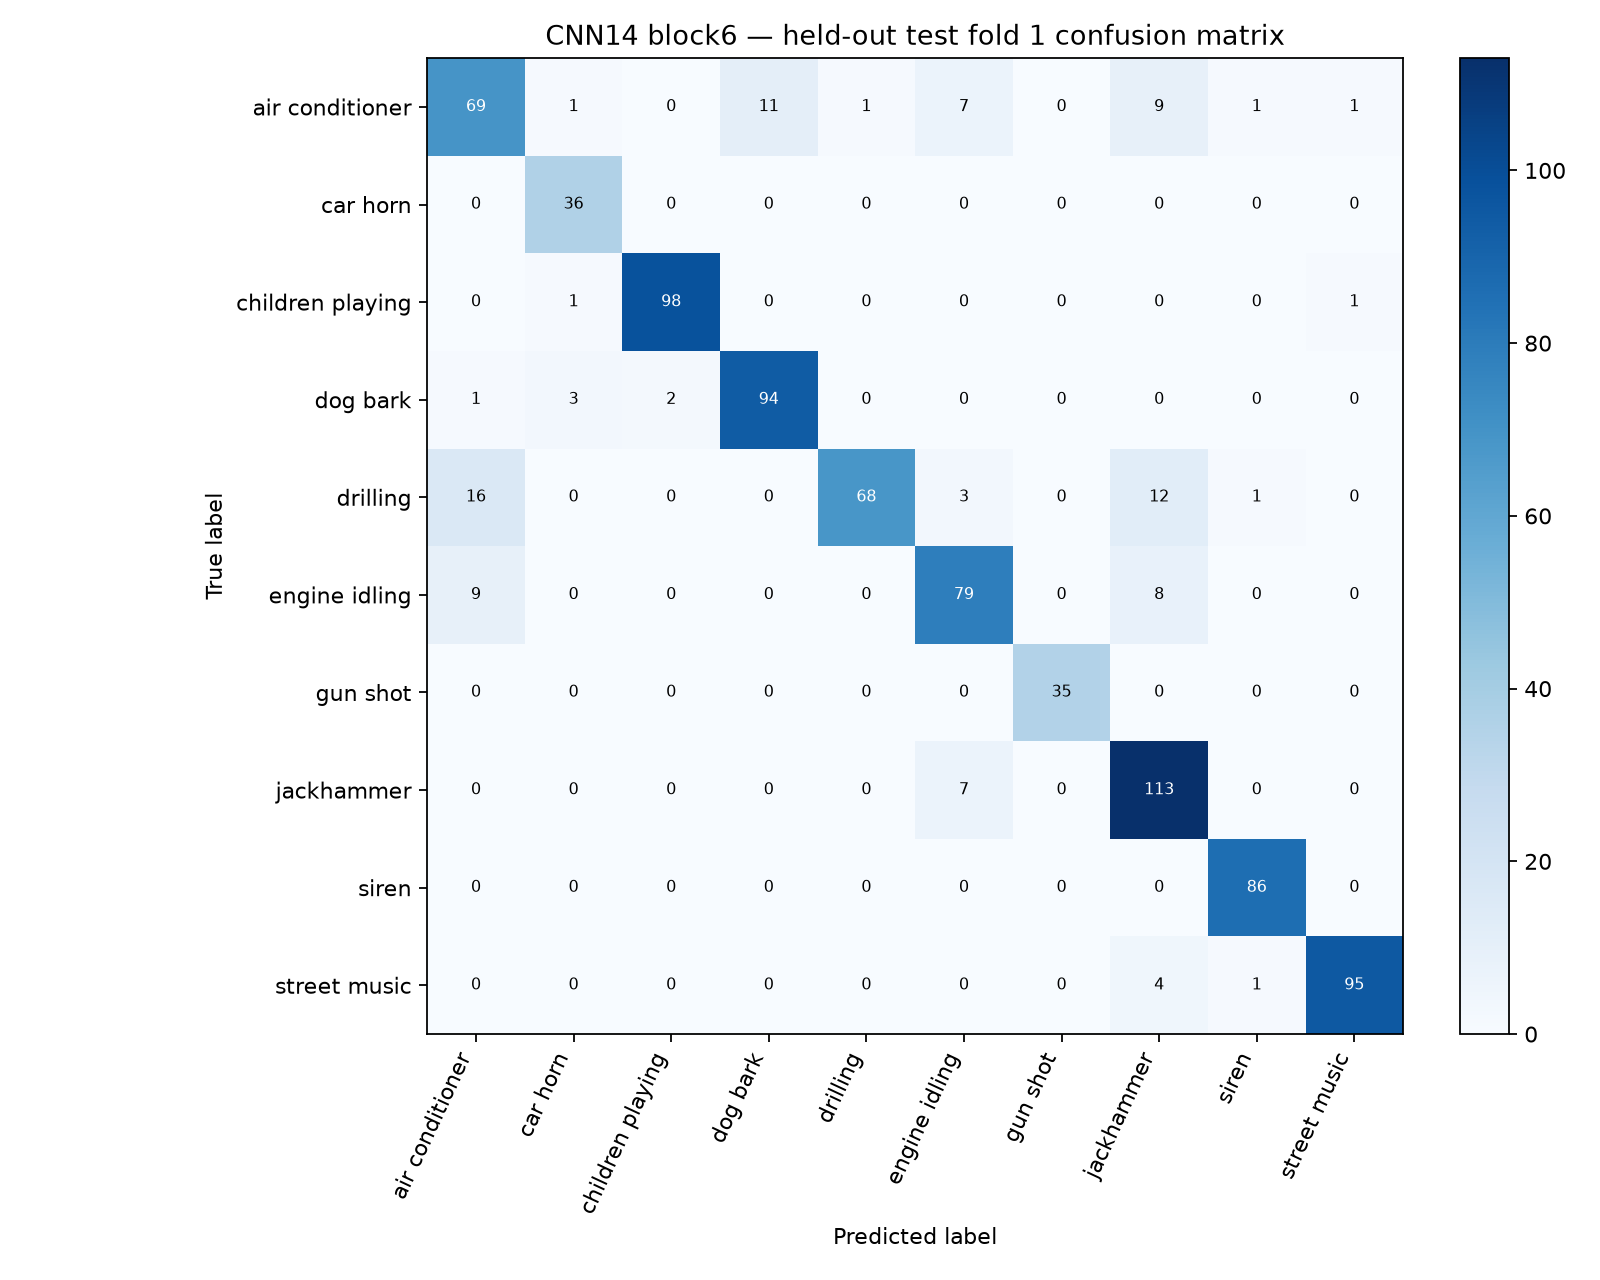

In [14]:
STAGE5_DIR = ROOT/'results'/'stage5'
completed = []
if STAGE5_DIR.is_dir():
    for fn in STAGE5_DIR.glob('*/evaluation_summary.json'):
        try:
            result = json.loads(fn.read_text(encoding='utf-8'))
            if result.get('test_evaluated') is True and result.get('config') == 'block6':
                completed.append((fn.parent,result))
        except (OSError,ValueError): pass
if completed:
    for folder,result in sorted(completed, key=lambda x: str(x[0])):
        print('Selected evaluation:', folder)
        display(pd.DataFrame([{
            'test_fold': result['test_fold'], 'n_test': result['test_samples'],
            'accuracy':result['accuracy'],'macro_f1':result['macro_f1'],
            'macro_precision':result['macro_precision'],'macro_recall':result['macro_recall'],
            'macro_specificity_ovr':result['macro_specificity_ovr'],
            'macro_roc_auc_ovr':result['macro_roc_auc_ovr']}]))
        display(pd.read_csv(folder/'per_class_metrics.csv'))
        display(Image(filename=str(folder/'confusion_matrix.png'),width=850))
else:
    print('Stage 5 not evaluated yet. This is expected before the one-time test step.')

## 9 · Optional README synchronization

The opt-in cell can update the managed faculty evidence section in the root README. Our public landing page is intentionally concise, so **inspect the README diff before committing** an automatically generated update.

Keep `UPDATE_ROOT_README = False` for routine review, then save the notebook with **Ctrl+S**.


In [15]:
if UPDATE_ROOT_README:
    root_readme = ROOT/'README.md'
    start_marker = '<!-- BEGIN AUTOMATED STAGE4_STAGE5_EVIDENCE -->'
    end_marker = '<!-- END AUTOMATED STAGE4_STAGE5_EVIDENCE -->'
    stage5_lines = ['- **Stage 5 held-out test:** pending (test fold 1 not evaluated in this notebook session).']
    if completed:
        folder, evaluated = sorted(completed,key=lambda x:str(x[0]))[-1]
        stage5_lines = [
            f"- **Stage 5 held-out fold {evaluated['test_fold']}**: accuracy **{evaluated['accuracy']:.2%}**, "
            f"macro-F1 **{evaluated['macro_f1']:.4f}**, macro ROC-AUC (OvR) **{evaluated['macro_roc_auc_ovr']}**.",
            f"- Evidence: `{folder.relative_to(ROOT) / 'evaluation_summary.json'}`; test metrics are *not* used for tuning.",
        ]
    content = '\n'.join([
       start_marker,
       '## Latest verified experiments (27 October 2026)',
       '- Three genuine Stage 4 full-fold runs completed: train folds 3–10; validation fold 2; test fold 1 held aside.',
       '- Best validation checkpoint is epoch 4 for all configurations, chosen by macro-F1.',
       '- **head:** validation accuracy **87.73%**, macro-F1 **0.8638**, 20,490 trainable parameters.',
       '- **fc1:** validation accuracy **88.06%**, macro-F1 **0.8668**, 4,216,842 trainable parameters.',
       '- **block6:** validation accuracy **90.65%**, macro-F1 **0.9010**, 60,848,138 trainable parameters.',
       '- The selected model for one-time held-out evaluation is **block6**, from validation fold 2; it is NOT multi-fold performance.',
       '- Validation loss rises after epoch 4; online training and evaluation accuracy are not directly interchangeable.',
       '- Five Freesound source IDs span official folds; this source-isolation caveat remains disclosed.',
       *stage5_lines,
       '- Detailed metrics and plots: `reports/stage4_comparison/`.',
       end_marker,
    ])
    original = root_readme.read_text(encoding='utf-8') if root_readme.is_file() else '# Deep Learning Framework for Environmental Sound Recognition Using PyTorch\n'
    if start_marker in original and end_marker in original:
        a=original.index(start_marker)
        b=original.index(end_marker)+len(end_marker)
        updated = original[:a]+content+original[b:]
    else:
        # Insert the newest status directly under the project title, keeping
        # older historical sections and user-authored diary text unchanged.
        first_line_end = original.find('\n')
        if first_line_end < 0:
            updated = original.rstrip()+'\n\n'+content+'\n'
        else:
            updated = original[:first_line_end+1]+'\n'+content+'\n\n'+original[first_line_end+1:]
    root_readme.write_text(updated,encoding='utf-8')
    print('Updated bounded evidence section only:',root_readme)
else:
    print('README left unchanged (set UPDATE_ROOT_README=True to synchronize).')

README left unchanged (set UPDATE_ROOT_README=True to synchronize).


## 10 · Conclusions and handoff

**CO3:** The selected partial-CNN14 model achieved **88.55% accuracy**, **0.8964 macro-F1** and **0.9909 macro OvR ROC-AUC** on held-out fold 1. Per-class support and confusions are available in the report.

**CO5:** `block6` improves validation macro-F1 versus frozen features (**0.9010 vs 0.8638**), with far more trainable parameters and runtime. This is a controlled freezing-depth result, not a newly invented network.

**CO4:** Use [Notebook 03](03_CO4_CO5_Faculty_Submission.ipynb) and [the original-paper comparison](../docs/CO4_PUBLISHED_METHODS.md) to contextualize results; published multi-fold accuracies are **not directly comparable** with this one-fold score.

**Limits:** One held-out fold, one seed, no ten-fold confidence estimate, known cross-fold source-ID overlap. No separate head/`fc1` test-fold scores were generated.

**Next for reviewers:** read Notebook 03, the [faculty checklist](../docs/FACULTY_SUBMISSION_CHECKLIST.md), and [reproduction guide](../docs/REPRODUCIBILITY.md). Do not rerun final test inference as a tuning loop.
